# Proyecto final · Clasificación de comentarios de un casino (baseline TF-IDF frente a BETO)
**Curso:** Procesamiento de Lenguaje Natural · Universidad EAN · Equipo de consultoría: Machine Learning, Ciencia de Datos y Gerencia en IA

**Decisión que apoya.** Qué comentarios de clientes requieren atención humana primero y cuáles se pueden procesar de forma automática. El sistema recibe un comentario y devuelve una clase, una confianza y una acción (automática o revisión humana).

**Tarea.** Clasificar el sentimiento general de cada comentario en cuatro clases: `negativa` (la queja, clase crítica), `mixta`, `positiva` y `no_mencionado`.

**Pregunta central.** ¿Un Transformer preentrenado en español (BETO) justifica su costo, riesgo y complejidad frente a un baseline TF-IDF con un clasificador lineal, y qué parte de los casos puede decidir sin ayuda de una persona?

**Datos.** `data/corpus_casinos_2100.csv`: 2.079 reseñas de Google Maps (de las 2.100 del corpus del curso), con partición 1.455 / 312 / 312. La ficha está en `data/DATA_CARD.md`.

## Cómo ejecutarlo
- **En tu computador (sin GPU):** abre el notebook desde la carpeta `notebooks/` y ejecuta todo. Entrena y evalúa los baselines y analiza todo. La sección 6 (BETO) **lee los resultados** de `results/beto_*` si existen; si no, lo indica y sigue.
- **En Google Colab con GPU (T4):** sube el notebook y los archivos de `data/` (`corpus_casinos_2100.csv` y `casos_robustez.csv`), activa la GPU y ejecuta todo. La sección 6 entrena BETO (6 corridas, unos 10 a 15 minutos) y guarda `results_colab.zip` con los resultados. Descomprímelo en `results/` y vuelve a ejecutar el notebook en tu computador.

## Reglas que se respetan
1. **Semilla 42** (y 43 y 44 para medir variabilidad).
2. **El test se usa una sola vez**, en la sección 8, solo con los modelos finalistas. Todo lo demás (elegir modelo, umbrales, errores, robustez) se hace con **validación**.
3. Todo se ajusta solo con **train** (vocabulario, pesos por clase, umbral de abstención con validación).
4. Mismos datos, misma partición y mismas métricas para todos los modelos.
5. Las metas de aceptación son **provisionales**: Gerencia IA debe validarlas con el cliente.

## 1. Entorno y parámetros
**Qué hacemos:** importamos las librerías, fijamos la semilla y reunimos en una celda todo lo ajustable.
**Por qué:** con los mismos parámetros y semillas, cualquier integrante obtiene los mismos resultados. Con GPU puede haber pequeñas diferencias aun con la misma semilla.

In [1]:
import os, re, sys, json, time, random, unicodedata, warnings, importlib.util, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline, make_union
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
import sklearn, joblib

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 100)
SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA)
EN_COLAB = 'google.colab' in sys.modules
HF_OK = importlib.util.find_spec('transformers') is not None and importlib.util.find_spec('torch') is not None
GPU = False
if HF_OK:
    import torch
    GPU = torch.cuda.is_available()
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| Colab:', EN_COLAB)
print('Transformers disponible:', HF_OK, '| GPU:', GPU)

Python 3.11.9 | scikit-learn 1.9.1 | pandas 3.0.6 | Colab: False
Transformers disponible: False | GPU: False


In [2]:
# ---- Parámetros (todo lo ajustable está aquí) ----
CLASES = ['negativa', 'mixta', 'positiva', 'no_mencionado']      # orden fijo de las probabilidades
IDX = {c: i for i, c in enumerate(CLASES)}
CRITICA = 'negativa'
SEMILLAS = [42, 43, 44]
# BETO
CHECKPOINT = 'dccuchile/bert-base-spanish-wwm-cased'
CONFIGS_BETO = {'beto_128': dict(max_len=128, minusculas=False),     # configuración del taller de la sesión 4
                'beto_128_min': dict(max_len=128, minusculas=True)}  # corrige la fragilidad ante MAYÚSCULAS
LR, BATCH, EPOCAS, WEIGHT_DECAY, WARMUP = 2e-5, 16, 3, 0.01, 0.1
ENTRENAR_BETO = HF_OK and GPU          # solo se entrena si hay GPU; si no, se leen los resultados guardados
# Metas de aceptación PROVISIONALES (Gerencia IA debe validarlas con el cliente)
META = {'mejora_f1': 0.02, 'recall_critica': 0.90, 'cobertura': 0.75, 'latencia_p95_ms': 150}
BOOTSTRAP = 2000
# Rutas relativas (funcionan igual desde notebooks/ o en Colab si subes los archivos a /content)
def buscar(nombre, carpetas=('.', '../data', 'data', '/content', '../results', 'results')):
    for c in carpetas:
        r = os.path.join(c, nombre)
        if os.path.exists(r): return r
    return None
CARPETA_RESULTADOS = '../results' if os.path.isdir('../results') else 'results'
def ruta_res(n): return os.path.join(CARPETA_RESULTADOS, n)
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
print('Resultados se guardan en:', os.path.abspath(CARPETA_RESULTADOS))

Resultados se guardan en: R:\EAN\Procesamiento de Lenguaje Natural\Proyecto Final\proyecto_final_casinos_nlp\results


## 2. Datos: carga y verificación
**Qué hacemos:** cargamos el corpus y comprobamos que cumple lo declarado en la ficha: particiones, clases y ausencia de textos idénticos entre particiones.
**Por qué:** si un texto del examen ya estaba en entrenamiento, el resultado sale inflado. Aquí solo **verificamos**; la partición ya se construyó por grupos de texto idéntico (`src/construir_dataset.py`).

In [3]:
ruta = buscar('corpus_casinos_2100.csv')
if ruta is None and EN_COLAB:
    from google.colab import files
    print('Sube corpus_casinos_2100.csv y casos_robustez.csv'); files.upload(); ruta = buscar('corpus_casinos_2100.csv')
assert ruta, 'No se encontró corpus_casinos_2100.csv'
df = pd.read_csv(ruta, encoding='utf-8-sig')
ASPECTOS = [c for c in df.columns if '#' in c]
assert df.id.is_unique and set(df.sentimiento) == set(CLASES)
assert df.groupby('grupo_texto').particion.nunique().max() == 1, 'un grupo de textos idénticos está en dos particiones'
tr = df[df.particion == 'train'].reset_index(drop=True)
va = df[df.particion == 'validation'].reset_index(drop=True)
te = df[df.particion == 'test'].reset_index(drop=True)
for t_ in (tr, va, te): t_['y'] = t_.sentimiento.map(IDX)
ytr, yva, yte = tr.y.values, va.y.values, te.y.values
tabla = pd.crosstab(df.sentimiento, df.particion).reindex(CLASES)[['train', 'validation', 'test']]
tabla['total'] = tabla.sum(axis=1); tabla['%'] = (tabla.total / tabla.total.sum() * 100).round(1)
display(tabla)
print(f'Total: {len(df)} reseñas | train {len(tr)} · validación {len(va)} · test {len(te)}')

particion,train,validation,test,total,%
sentimiento,,,,,
negativa,271,57,59,387,18.6
mixta,91,21,19,131,6.3
positiva,856,183,183,1222,58.8
no_mencionado,237,51,51,339,16.3


Total: 2079 reseñas | train 1455 · validación 312 · test 312


## 3. Análisis exploratorio (EDA)
**Qué hacemos:** miramos la distribución de clases, la longitud de los textos, el periodo, los aspectos y ejemplos de cada clase.
**Por qué:** la forma de los datos decide la métrica (clases desbalanceadas), la longitud máxima del modelo y los riesgos (duplicados, ruido de etiquetas).

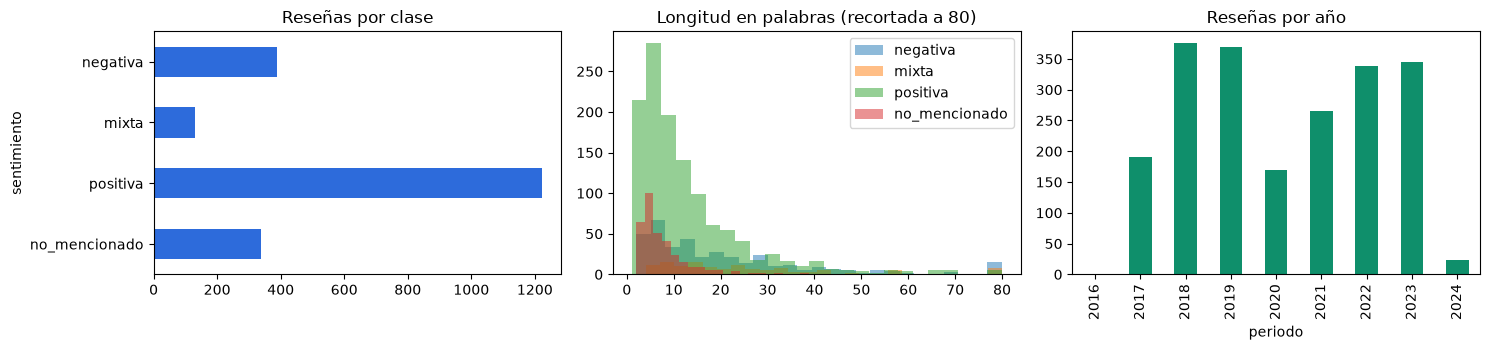

,count,mean,50%,90%,max
sentimiento,,,,,
negativa,387.0,23.1,14.0,46.0,256.0
mixta,131.0,28.9,21.0,56.0,209.0
positiva,1222.0,13.2,9.0,28.0,143.0
no_mencionado,339.0,7.9,6.0,15.0,48.0


Percentiles de longitud (palabras): P50 = 9 | P90 = 32 | P95 = 44 | P99 = 86
Reseñas con más de 64 palabras: 46 | con más de 128: 9


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tabla.total.plot.barh(ax=ax[0], color='#2D6BDB'); ax[0].set_title('Reseñas por clase'); ax[0].invert_yaxis()
for c in CLASES: ax[1].hist(df[df.sentimiento == c].n_palabras.clip(upper=80), bins=25, alpha=.5, label=c)
ax[1].set_title('Longitud en palabras (recortada a 80)'); ax[1].legend()
df.periodo.str[:4].value_counts().sort_index().plot.bar(ax=ax[2], color='#0F8F6B'); ax[2].set_title('Reseñas por año')
plt.tight_layout(); plt.show()
long_ = df.groupby('sentimiento').n_palabras.describe(percentiles=[.5, .9]).round(1).reindex(CLASES)[['count', 'mean', '50%', '90%', 'max']]
display(long_)
print('Percentiles de longitud (palabras): P50 =', int(df.n_palabras.quantile(.5)), '| P90 =', int(df.n_palabras.quantile(.9)),
      '| P95 =', int(df.n_palabras.quantile(.95)), '| P99 =', int(df.n_palabras.quantile(.99)))
print('Reseñas con más de 64 palabras:', int((df.n_palabras > 64).sum()), '| con más de 128:', int((df.n_palabras > 128).sum()))

In [5]:
# Aspectos: cuántas reseñas tienen opinión positiva o negativa en cada uno (la tarea usa el sentimiento general, no los aspectos)
asp = pd.DataFrame({'positiva': (df[ASPECTOS] == 'positiva').sum(), 'negativa': (df[ASPECTOS] == 'negativa').sum()})
asp['con opinión'] = asp.sum(axis=1); display(asp.sort_values('con opinión', ascending=False))
# Palabras más asociadas a cada clase (log-odds frente al resto)
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=8, ngram_range=(1, 1), token_pattern=r'(?u)\b[^\W\d_]{3,}\b'); Xc = cv.fit_transform(tr.texto); voc = np.array(cv.get_feature_names_out())
filas = {}
for c in CLASES:
    m = (tr.sentimiento == c).values
    a_ = np.asarray(Xc[m].sum(0)).ravel() + 1; b_ = np.asarray(Xc[~m].sum(0)).ravel() + 1
    lo = np.log(a_ / a_.sum()) - np.log(b_ / b_.sum()); filas[c] = ', '.join(voc[np.argsort(-lo)[:10]])
display(pd.Series(filas, name='palabras más características (train)').to_frame())
print('Ejemplos:')
for c in CLASES:
    print('--', c); [print('   ·', t[:140]) for t in tr[tr.sentimiento == c].texto.sample(3, random_state=SEMILLA)]

,positiva,negativa,con opinión
ambiente_restaurate#gastronomia,926,80,1006
calidad#slot,163,238,401
calidad#gastronomia,298,79,377
ambiente_sala#slots,223,75,298
atencion#gastronomia,164,82,246
atencion#atencion_cliente,101,114,215
precio#slot,4,205,209
calidad#limpieza,136,67,203
precio#gastronomia,41,56,97
calidad#seguridad,46,27,73


,palabras más características (train)
negativa,"desastre, funcionan, mala, robo, vergüenza, sucio, ellos, mal, nadie, caro"
mixta,"cantidad, precios, malo, después, casi, deja, barato, zona, tarjeta, deberían"
positiva,"exelente, tarde, amigos, lindos, imponente, vivo, ambiente, limpio, entretenido, entretenimiento"
no_mencionado,"aires, edificio, hipodromo, primera, distraerse, ciudad, abierto, caballo, interesante, pandemia"


Ejemplos:
-- negativa
   · No tenes personal .desperdicio por todos lados . El estacionamiento muy caro 3000 peso una barbaridad . Las máquinas no pagan mucho porque s
   · No podes fumar mientras toma un cafè; y estas al aire libre
   · Mucha gente... Poca limpieza.. las máquinas con desperfectos
-- mixta
   · Buen ambiente; lastima que por tener ropa deportiva me pidieron el DNI más de 1 vez💔
   · Muy bueno el salón de slots. Lo malo los precios de los bares y restaurantes
   · Me gusta mucho la atención u la gastronomía pero me gustaría mucho más si las máquinas pagarían
-- positiva
   · Si tenes suerte es lo mejor
   · Muy bien mantenido
   · Un lugar muy lindo para disfrutar en familia.
-- no_mencionado
   · Para entretenerse y pasear por dentro y por fuera!!!
   · Excelente lugar para divertirse y pasarla bien
   · Buen lugar para entretener


**Lectura del EDA.**
- `positiva` domina (≈ 59 %): un modelo que siempre dijera "positiva" acertaría ~59 % sin aprender nada. Por eso la métrica principal es el **F1 macro** y se usan **pesos por clase**.
- `mixta` es la clase más pequeña (≈ 6 %) y las reseñas mixtas son más largas: su métrica será inestable.
- La mediana es de 9 palabras: casi todo cabe en 64 tokens. Solo unas pocas reseñas largas se recortarían.
- Todas las reseñas son de un solo lugar y de Google Maps: lo que se concluya **no se puede extender** a otras cadenas o canales sin repetir la prueba.

## 4. Preparación: métricas y utilidades
**Qué hacemos:** definimos una sola función de métricas y las utilidades de abstención y calibración, para usarlas con todos los modelos.
**Por qué:** comparar bien exige medir todo de la misma manera. `recall_negativa` mide cuántas quejas reales se encuentran; `f1_mixta`, la clase que más depende del contexto.

In [6]:
def metricas(y, P):
    P = np.asarray(P, float); P = P / P.sum(1, keepdims=True); pred = P.argmax(1); et = list(range(len(CLASES)))
    f1c = f1_score(y, pred, average=None, labels=et, zero_division=0); rc = recall_score(y, pred, average=None, labels=et, zero_division=0)
    return dict(f1_macro=f1_score(y, pred, average='macro', labels=et, zero_division=0), recall_negativa=rc[IDX[CRITICA]],
                f1_negativa=f1c[IDX['negativa']], f1_mixta=f1c[IDX['mixta']], f1_positiva=f1c[IDX['positiva']], f1_no_mencionado=f1c[IDX['no_mencionado']],
                exactitud=accuracy_score(y, pred), log_loss=log_loss(y, P, labels=et))

def ece(y, P, bins=10):
    P = np.asarray(P); conf = P.max(1); ok = (P.argmax(1) == y); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return e

def regla_revision(P, tau, t_neg):
    """Una persona revisa el caso si la confianza es baja o si hay probabilidad alta de queja."""
    P = np.asarray(P); return (P.max(1) < tau) | (P[:, IDX[CRITICA]] >= t_neg)

def evaluar_regla(y, P, tau, t_neg):
    rev = regla_revision(P, tau, t_neg); pred = P.argmax(1); queja = (y == IDX[CRITICA]); ok = (pred == y)
    auto = ~rev
    return dict(tau=tau, t_neg=t_neg, cobertura=auto.mean(), revision=rev.mean(),
                exactitud_automatica=ok[auto].mean() if auto.any() else np.nan,
                recall_queja_directo=((pred == IDX[CRITICA]) & queja).sum() / queja.sum(),
                recall_queja_con_revision=((((pred == IDX[CRITICA]) | rev) & queja).sum() / queja.sum()))

def elegir_regla(y, P, meta_recall):
    """Elige (tau, t_neg) con la VALIDACIÓN: la regla que menos casos manda a revisión y aún cumple el recall objetivo."""
    mejores = []
    for tau in np.arange(0.40, 0.96, 0.05):
        for t_neg in (0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60, 1.01):
            mejores.append(evaluar_regla(y, P, round(tau, 2), t_neg))
    g_ = pd.DataFrame(mejores); ok = g_[g_.recall_queja_con_revision >= meta_recall]
    return (ok.sort_values(['revision', 'tau']).iloc[0] if len(ok) else g_.sort_values('recall_queja_con_revision', ascending=False).iloc[0]), g_

def boot_diff(y, Pa, Pb, B=BOOTSTRAP, seed=SEMILLA):
    """Bootstrap pareado: intervalo del F1 macro de cada modelo y de su diferencia (b - a)."""
    rng = np.random.default_rng(seed); n = len(y); pa, pb = Pa.argmax(1), Pb.argmax(1); fa, fb = [], []
    for _ in range(B):
        i = rng.integers(0, n, n)
        fa.append(f1_score(y[i], pa[i], average='macro', labels=list(range(4)), zero_division=0))
        fb.append(f1_score(y[i], pb[i], average='macro', labels=list(range(4)), zero_division=0))
    fa, fb = np.array(fa), np.array(fb); d = fb - fa
    q = lambda v: (np.percentile(v, 2.5), np.percentile(v, 97.5))
    return dict(a=q(fa), b=q(fb), diff=d.mean(), diff_ic=q(d), p_b_mejor=(d > 0).mean())

## 5. Baseline obligatorio: TF-IDF + clasificador lineal
**Qué hacemos:** entrenamos varios baselines clásicos con **solo train** y los medimos en **validación**: TF-IDF de palabras, de caracteres y de ambos, con regresión logística, SVM lineal y Naive Bayes. El campeón del baseline es el mejor con regresión logística (da probabilidades, que necesitamos para abstener).
**Por qué:** el baseline es la vara de medir. TF-IDF **no es una red neuronal**: es la alternativa simple con la que se compara BETO. Si BETO no la supera con claridad, no justifica su costo.

In [7]:
W = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Ch = lambda: TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True)
LRc = lambda: LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEMILLA)
CANDIDATOS = {
    'TF-IDF palabras + regresión logística': Pipeline([('v', W()), ('c', LRc())]),
    'TF-IDF caracteres + regresión logística': Pipeline([('v', Ch()), ('c', LRc())]),
    'TF-IDF caracteres y palabras + regresión logística': Pipeline([('v', make_union(W(), Ch())), ('c', LRc())]),
    'TF-IDF caracteres + SVM lineal': Pipeline([('v', Ch()), ('c', LinearSVC(class_weight='balanced', random_state=SEMILLA))]),
    'TF-IDF palabras + SVM lineal': Pipeline([('v', W()), ('c', LinearSVC(class_weight='balanced', random_state=SEMILLA))]),
    'TF-IDF palabras + Naive Bayes': Pipeline([('v', W()), ('c', ComplementNB())]),
}
filas, modelos_base, tiempos = [], {}, {}
for nombre, pipe in CANDIDATOS.items():
    t0 = time.time(); pipe.fit(tr.texto, ytr); seg = time.time() - t0
    pred = pipe.predict(va.texto); modelos_base[nombre] = pipe; tiempos[nombre] = seg
    et = list(range(4))
    filas.append(dict(modelo=nombre, f1_macro_val=f1_score(yva, pred, average='macro', labels=et, zero_division=0),
                      recall_negativa_val=recall_score(yva, pred, labels=[IDX[CRITICA]], average=None, zero_division=0)[0],
                      f1_mixta_val=f1_score(yva, pred, average=None, labels=et, zero_division=0)[IDX['mixta']],
                      con_probabilidades=hasattr(pipe, 'predict_proba'), segundos_entrenar=seg))
res_base = pd.DataFrame(filas).sort_values('f1_macro_val', ascending=False).reset_index(drop=True)
display(res_base.round(3)); res_base.to_csv(ruta_res('baselines_validacion.csv'), index=False)
LR_NOMBRES = [n for n in res_base.modelo if 'regresión logística' in n]
BASE_NOMBRE = LR_NOMBRES[0]                       # campeón del baseline: mejor regresión logística en VALIDACIÓN
base = modelos_base[BASE_NOMBRE]
Pva_base = base.predict_proba(va.texto)
print('Baseline campeón (validación):', BASE_NOMBRE)

,modelo,f1_macro_val,recall_negativa_val,f1_mixta_val,con_probabilidades,segundos_entrenar
0,TF-IDF caracteres y palabras + regresión logística,0.646,0.772,0.488,True,2.056
1,TF-IDF caracteres + regresión logística,0.633,0.754,0.500,True,1.620
2,TF-IDF palabras + regresión logística,0.632,0.754,0.511,True,0.531
3,TF-IDF caracteres + SVM lineal,0.610,0.807,0.294,False,1.320
4,TF-IDF palabras + SVM lineal,0.567,0.737,0.267,False,0.183
5,TF-IDF palabras + Naive Bayes,0.461,0.860,0.000,True,0.196


Baseline campeón (validación): TF-IDF caracteres y palabras + regresión logística


**Cómo leerlo.** Las diferencias de pocas centésimas entre baselines no son concluyentes (la validación tiene 312 reseñas). Se escoge el mejor con regresión logística por una razón práctica: entrega probabilidades. El SVM y Naive Bayes quedan como referencia: muestran que el resultado no depende de un solo clasificador.

## 6. Modelo avanzado: BETO ajustado (fine-tuning)
**Qué hacemos:** ajustamos BETO (un BERT preentrenado en español) con la cabeza de clasificación de 4 clases. Dos configuraciones, cada una con 3 semillas: `beto_128` (la del taller de la sesión 4) y `beto_128_min` (el texto se pasa a minúsculas antes de entrar al modelo, porque BETO distingue mayúsculas de minúsculas y mostró fragilidad ante textos en MAYÚSCULAS).
**Parámetros** (los del taller): learning rate 2e-5, batch 16, 3 épocas, weight decay 0,01, warmup 10 %, `max_length` 128, pérdida con pesos por clase y selección de la mejor época por F1 macro de validación.
**Cómo se ejecuta:** con GPU, esta sección **entrena** y guarda sus resultados en `results/beto_*`. Sin GPU, **lee** esos resultados si existen. Así el notebook se ejecuta de inicio a fin en cualquier equipo.

> El **test no se toca aquí**: las probabilidades de test del campeón se calculan en la sección 8, una sola vez.

In [8]:
RES = CARPETA_RESULTADOS
def ruta_res(n): return os.path.join(RES, n)
BETO_LISTO = False
if ENTRENAR_BETO:
    import gc, shutil, inspect
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer, set_seed
    from sklearn.utils.class_weight import compute_class_weight
    PESOS = torch.tensor(compute_class_weight('balanced', classes=np.arange(4), y=ytr), dtype=torch.float)
    print('Pesos por clase (solo train):', dict(zip(CLASES, PESOS.numpy().round(2))))
    CARPETA_MODELOS = '/content/modelos_beto' if EN_COLAB else os.path.join(RES, 'modelos_beto'); os.makedirs(CARPETA_MODELOS, exist_ok=True)

    def prep(textos, minusculas): return [t.lower() if minusculas else t for t in textos]
    class DS(torch.utils.data.Dataset):
        def __init__(self, tok, textos, y, max_len):
            enc = tok(list(textos), truncation=True, max_length=max_len)
            self.items = [{k: enc[k][i] for k in enc.keys()} for i in range(len(enc['input_ids']))]; self.y = [int(v) for v in y]
        def __len__(self): return len(self.y)
        def __getitem__(self, i): return dict(self.items[i], labels=self.y[i])
    class PesoTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kw):
            lab = inputs.get('labels'); out = model(**{k: v for k, v in inputs.items() if k != 'labels'})
            loss = torch.nn.functional.cross_entropy(out.logits, lab, weight=PESOS.to(out.logits.device))
            return (loss, out) if return_outputs else loss
    def compute_metrics(ep):
        lg, lab = ep; p = np.asarray(lg).argmax(-1)
        return {'f1_macro': f1_score(lab, p, average='macro', labels=list(range(4)), zero_division=0)}
    def softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
    def argumentos(carpeta, semilla):
        p = inspect.signature(TrainingArguments.__init__).parameters
        kw = dict(output_dir=carpeta, learning_rate=LR, per_device_train_batch_size=BATCH, per_device_eval_batch_size=64, num_train_epochs=EPOCAS,
                  weight_decay=WEIGHT_DECAY, save_strategy='epoch', load_best_model_at_end=True, metric_for_best_model='f1_macro', greater_is_better=True,
                  save_total_limit=1, seed=semilla, report_to='none', logging_strategy='no', disable_tqdm=True, fp16=GPU)
        kw['eval_strategy' if 'eval_strategy' in p else 'evaluation_strategy'] = 'epoch'
        if 'warmup_ratio' in p: kw['warmup_ratio'] = WARMUP
        else: kw['warmup_steps'] = WARMUP
        return TrainingArguments(**{k: v for k, v in kw.items() if k in p})
    class Predictor:
        def __init__(self, carpeta, max_len, minusculas, dev=None):
            self.tok = AutoTokenizer.from_pretrained(carpeta); self.m = AutoModelForSequenceClassification.from_pretrained(carpeta)
            self.max_len, self.min, self.dev = max_len, minusculas, dev or ('cuda' if GPU else 'cpu'); self.m.to(self.dev).eval()
        @torch.inference_mode()
        def __call__(self, textos, batch=64):
            textos = prep(list(textos), self.min); out = []
            for i in range(0, len(textos), batch):
                enc = self.tok(textos[i:i + batch], truncation=True, max_length=self.max_len, padding=True, return_tensors='pt').to(self.dev)
                out.append(torch.softmax(self.m(**enc).logits.float(), -1).cpu().numpy())
            return np.vstack(out)
    def carpeta_modelo(cfg, sem): return os.path.join(CARPETA_MODELOS, f'{cfg}_s{sem}')

    corridas, val_probs = [], []
    for cfg, par in CONFIGS_BETO.items():
        for sem in SEMILLAS:
            set_seed(sem); tok = AutoTokenizer.from_pretrained(CHECKPOINT)
            dtr = DS(tok, prep(tr.texto, par['minusculas']), ytr, par['max_len']); dva = DS(tok, prep(va.texto, par['minusculas']), yva, par['max_len'])
            modelo = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=4, id2label=dict(enumerate(CLASES)), label2id=IDX)
            tp = inspect.signature(Trainer.__init__).parameters
            trainer = PesoTrainer(model=modelo, args=argumentos(os.path.join(carpeta_modelo(cfg, sem), '_ckpt'), sem), train_dataset=dtr, eval_dataset=dva,
                                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
                                  **{('processing_class' if 'processing_class' in tp else 'tokenizer'): tok})
            t0 = time.time(); trainer.train(); seg = time.time() - t0
            hist = [h for h in trainer.state.log_history if 'eval_f1_macro' in h]
            P = softmax(trainer.predict(dva).predictions); m = metricas(yva, P)
            trainer.save_model(carpeta_modelo(cfg, sem)); tok.save_pretrained(carpeta_modelo(cfg, sem)); shutil.rmtree(os.path.join(carpeta_modelo(cfg, sem), '_ckpt'), ignore_errors=True)
            corridas.append(dict(config=cfg, semilla=sem, **{k + '_val': round(v, 4) for k, v in m.items()}, segundos_entrenamiento=round(seg, 1),
                                 mejor_epoca=int(np.argmax([h['eval_f1_macro'] for h in hist])) + 1, parametros_M=round(sum(p.numel() for p in modelo.parameters()) / 1e6, 1)))
            val_probs.append(pd.DataFrame(P, columns=CLASES).assign(config=cfg, semilla=sem, id=va.id.values))
            print(f"{cfg} semilla {sem}: F1 macro val {m['f1_macro']:.3f} · recall queja {m['recall_negativa']:.3f} · {seg:.0f} s")
            del trainer, modelo; gc.collect(); torch.cuda.empty_cache()
    pd.DataFrame(corridas).to_csv(ruta_res('beto_corridas.csv'), index=False)
    pd.concat(val_probs).to_csv(ruta_res('beto_val_probs.csv'), index=False)
    BETO_LISTO = True
elif os.path.exists(ruta_res('beto_corridas.csv')) and os.path.exists(ruta_res('beto_val_probs.csv')):
    BETO_LISTO = True
    print('BETO: se leen los resultados guardados en', os.path.abspath(RES))
else:
    print('BETO: todavía no hay resultados. Ejecuta este notebook en Colab con GPU (ver la portada) y copia results_colab.zip en results/.')
    print('Mientras tanto, las secciones siguientes se calculan solo con el baseline.')

BETO: se leen los resultados guardados en R:\EAN\Procesamiento de Lenguaje Natural\Proyecto Final\proyecto_final_casinos_nlp\results


In [9]:
if BETO_LISTO:
    corr = pd.read_csv(ruta_res('beto_corridas.csv')); display(corr)
    resumen_beto = corr.groupby('config').agg(f1_macro_val=('f1_macro_val', 'mean'), f1_std=('f1_macro_val', 'std'), recall_negativa_val=('recall_negativa_val', 'mean'),
                                             f1_mixta_val=('f1_mixta_val', 'mean'), log_loss_val=('log_loss_val', 'mean'),
                                             segundos=('segundos_entrenamiento', 'mean'), parametros_M=('parametros_M', 'first')).round(4)
    display(resumen_beto)
    BETO_CFG = resumen_beto.f1_macro_val.idxmax()                 # campeón de BETO: mejor F1 macro medio en VALIDACIÓN
    print('Campeón de BETO (validación):', BETO_CFG)
    vp = pd.read_csv(ruta_res('beto_val_probs.csv'))
    def probs_val_beto(cfg, sem):
        x = vp[(vp.config == cfg) & (vp.semilla == sem)].set_index('id').loc[va.id.values]; return x[CLASES].values
    Pva_beto = probs_val_beto(BETO_CFG, SEMILLAS[0])
else:
    BETO_CFG = None; Pva_beto = None

,config,semilla,f1_macro_val,recall_negativa_val,f1_negativa_val,f1_mixta_val,f1_positiva_val,f1_no_mencionado_val,exactitud_val,log_loss_val,segundos_entrenamiento,mejor_epoca,parametros_M
0,beto_128,42,0.7101,0.8596,0.8673,0.5714,0.8433,0.5586,0.7756,0.5520,59.8,2,109.9
1,beto_128,43,0.7424,0.8596,0.8750,0.6538,0.8612,0.5794,0.7981,0.5709,75.1,2,109.9
2,beto_128,44,0.7257,0.8596,0.8522,0.6047,0.8611,0.5849,0.7949,0.5500,60.5,3,109.9
3,beto_128_min,42,0.7181,0.8070,0.8364,0.5882,0.8627,0.5849,0.7885,0.5634,75.4,3,109.9
4,beto_128_min,43,0.7209,0.8070,0.8440,0.6122,0.8611,0.5660,0.7885,0.5651,55.4,3,109.9
5,beto_128_min,44,0.7367,0.8596,0.8596,0.6364,0.8563,0.5946,0.7949,0.5618,57.9,3,109.9


,f1_macro_val,f1_std,recall_negativa_val,f1_mixta_val,log_loss_val,segundos,parametros_M
config,,,,,,,
beto_128,0.7261,0.0162,0.8596,0.6100,0.5576,65.1333,109.9
beto_128_min,0.7252,0.0100,0.8245,0.6123,0.5634,62.9000,109.9


Campeón de BETO (validación): beto_128


## 7. Selección del modelo final con validación
**Qué hacemos:** ponemos lado a lado el baseline campeón y BETO en **validación**, y elegimos qué modelos pasan a la medición final en test.
**Por qué:** el test es el examen final: no se mira para elegir. Aquí decide solo la validación.

In [10]:
filas = [dict(modelo='Baseline: ' + BASE_NOMBRE, **{k: round(v, 4) for k, v in metricas(yva, Pva_base).items()}, ece=round(ece(yva, Pva_base), 4))]
if BETO_LISTO:
    for cfg in CONFIGS_BETO:
        ms = [metricas(yva, probs_val_beto(cfg, s)) for s in SEMILLAS if len(vp[(vp.config == cfg) & (vp.semilla == s)])]
        filas.append(dict(modelo=f'BETO ({cfg}, media de {len(ms)} semillas)', **{k: round(float(np.mean([m[k] for m in ms])), 4) for k in ms[0]},
                          ece=round(float(np.mean([ece(yva, probs_val_beto(cfg, s)) for s in SEMILLAS])), 4)))
comp_val = pd.DataFrame(filas); display(comp_val); comp_val.to_csv(ruta_res('comparacion_validacion.csv'), index=False)
FINALISTAS = ['baseline'] + (['beto'] if BETO_LISTO else [])
print('Pasan a la medición final en test:', FINALISTAS)

,modelo,f1_macro,recall_negativa,f1_negativa,f1_mixta,f1_positiva,f1_no_mencionado,exactitud,log_loss,ece
0,Baseline: TF-IDF caracteres y palabras + regresión logística,0.6457,0.7719,0.7273,0.4878,0.8305,0.5370,0.7372,0.7048,0.1213
1,"BETO (beto_128, media de 3 semillas)",0.7261,0.8596,0.8648,0.6100,0.8552,0.5743,0.7895,0.5576,0.0500
2,"BETO (beto_128_min, media de 3 semillas)",0.7252,0.8246,0.8467,0.6123,0.8601,0.5818,0.7906,0.5634,0.0560


Pasan a la medición final en test: ['baseline', 'beto']


## 8. Evaluación final en test (una sola vez)
**Qué hacemos:** medimos en test **solo** al baseline campeón y, si hay resultados, a BETO. Reportamos métricas por clase, matrices de confusión, intervalos de confianza y la comparación.
**Por qué:** es el examen final. Se mide una vez; no se vuelve a ajustar nada después de verlo.

Para BETO, las probabilidades de test del campeón se calculan aquí (con GPU) o se leen de `results/beto_test_probs.csv`.

In [11]:
Pte_base = base.predict_proba(te.texto)
Pte_beto = None
if BETO_LISTO:
    if ENTRENAR_BETO:
        par = CONFIGS_BETO[BETO_CFG]; lista = []
        for sem in SEMILLAS:
            pr = Predictor(carpeta_modelo(BETO_CFG, sem), par['max_len'], par['minusculas']); lista.append(pd.DataFrame(pr(te.texto), columns=CLASES).assign(config=BETO_CFG, semilla=sem, id=te.id.values))
            del pr; gc.collect(); torch.cuda.empty_cache()
        pd.concat(lista).to_csv(ruta_res('beto_test_probs.csv'), index=False)
    if os.path.exists(ruta_res('beto_test_probs.csv')):
        tp_ = pd.read_csv(ruta_res('beto_test_probs.csv'))
        probs_te_beto = lambda sem: tp_[tp_.semilla == sem].set_index('id').loc[te.id.values][CLASES].values
        Pte_beto = probs_te_beto(SEMILLAS[0])
filas = [dict(modelo='Baseline: ' + BASE_NOMBRE, semilla='—', **{k: round(v, 4) for k, v in metricas(yte, Pte_base).items()})]
if Pte_beto is not None:
    for s in SEMILLAS: filas.append(dict(modelo=f'BETO ({BETO_CFG})', semilla=s, **{k: round(v, 4) for k, v in metricas(yte, probs_te_beto(s)).items()}))
res_test = pd.DataFrame(filas); display(res_test); res_test.to_csv(ruta_res('metricas_test.csv'), index=False)
if Pte_beto is not None:
    mb = res_test[res_test.modelo.str.startswith('BETO')]
    print(f"BETO, media de {len(mb)} semillas: F1 macro {mb.f1_macro.mean():.3f} ± {mb.f1_macro.std():.3f} | recall de quejas {mb.recall_negativa.mean():.3f}")
    print(f"Baseline: F1 macro {res_test.f1_macro.iloc[0]:.3f} | recall de quejas {res_test.recall_negativa.iloc[0]:.3f}")

,modelo,semilla,f1_macro,recall_negativa,f1_negativa,f1_mixta,f1_positiva,f1_no_mencionado,exactitud,log_loss
0,Baseline: TF-IDF caracteres y palabras + regresión logística,—,0.6260,0.7966,0.7833,0.3810,0.8398,0.5000,0.7436,0.7167
1,BETO (beto_128),42,0.6971,0.8644,0.8500,0.5532,0.8481,0.5370,0.7724,0.5628
2,BETO (beto_128),43,0.7043,0.8475,0.8696,0.5385,0.8433,0.5660,0.7756,0.5866
3,BETO (beto_128),44,0.7185,0.9153,0.8780,0.5778,0.8556,0.5625,0.7949,0.5344


BETO, media de 3 semillas: F1 macro 0.707 ± 0.011 | recall de quejas 0.876
Baseline: F1 macro 0.626 | recall de quejas 0.797


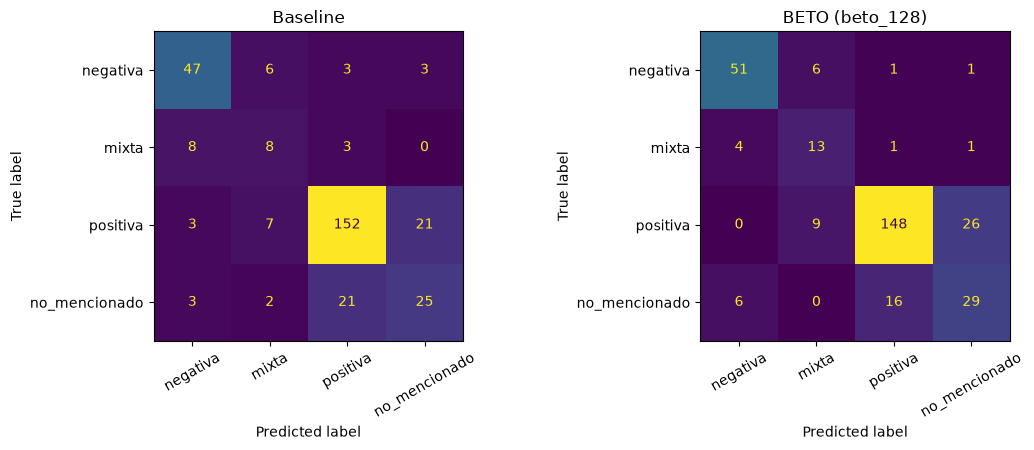

               precision    recall  f1-score   support

     negativa       0.77      0.80      0.78        59
        mixta       0.35      0.42      0.38        19
     positiva       0.85      0.83      0.84       183
no_mencionado       0.51      0.49      0.50        51

     accuracy                           0.74       312
    macro avg       0.62      0.63      0.63       312
 weighted avg       0.75      0.74      0.75       312



Baseline en test · F1 macro IC95 % [0.554, 0.690] · recall de quejas IC95 % [0.688, 0.894]


F1 macro baseline  IC95 % [0.554, 0.690]
F1 macro BETO      IC95 % [0.630, 0.757]
Diferencia BETO - baseline: +0.072  IC95 % [+0.003, +0.145] · BETO mejor en 98.0% de las remuestras


In [12]:
# Matrices de confusión en test
n_m = 1 + (Pte_beto is not None)
fig, axs = plt.subplots(1, n_m, figsize=(5.6 * n_m, 4.6)); axs = np.atleast_1d(axs)
for ax_, nombre, P in zip(axs, ['Baseline', f'BETO ({BETO_CFG})'], [Pte_base, Pte_beto]):
    if P is None: continue
    ConfusionMatrixDisplay(confusion_matrix(yte, P.argmax(1), labels=range(4)), display_labels=CLASES).plot(ax=ax_, colorbar=False, xticks_rotation=30)
    ax_.set_title(nombre)
plt.tight_layout(); plt.show()
print(classification_report(yte, Pte_base.argmax(1), target_names=CLASES, zero_division=0))
def boot_ci(y, P, B=BOOTSTRAP, seed=SEMILLA):
    rng = np.random.default_rng(seed); n = len(y); p = P.argmax(1); f, r = [], []
    for _ in range(B):
        i = rng.integers(0, n, n); f.append(f1_score(y[i], p[i], average='macro', labels=list(range(4)), zero_division=0))
        q = (y[i] == IDX[CRITICA]); r.append(((p[i] == IDX[CRITICA]) & q).sum() / max(1, q.sum()))
    return dict(f1_macro=[float(np.percentile(f, 2.5)), float(np.percentile(f, 97.5))], recall_negativa=[float(np.percentile(r, 2.5)), float(np.percentile(r, 97.5))])
ic_base = boot_ci(yte, Pte_base); json.dump(ic_base, open(ruta_res('ic_baseline.json'), 'w'))
print(f"Baseline en test · F1 macro IC95 % [{ic_base['f1_macro'][0]:.3f}, {ic_base['f1_macro'][1]:.3f}] · recall de quejas IC95 % [{ic_base['recall_negativa'][0]:.3f}, {ic_base['recall_negativa'][1]:.3f}]")
# Intervalos de confianza (bootstrap pareado) en test
if Pte_beto is not None:
    r = boot_diff(yte, Pte_base, Pte_beto)
    print(f"F1 macro baseline  IC95 % [{r['a'][0]:.3f}, {r['a'][1]:.3f}]")
    print(f"F1 macro BETO      IC95 % [{r['b'][0]:.3f}, {r['b'][1]:.3f}]")
    print(f"Diferencia BETO - baseline: {r['diff']:+.3f}  IC95 % [{r['diff_ic'][0]:+.3f}, {r['diff_ic'][1]:+.3f}] · BETO mejor en {r['p_b_mejor']:.1%} de las remuestras")
else:
    print('Sin BETO no hay comparación con intervalos todavía.')

## 9. Abstención, cobertura y calibración
**Qué hacemos:** definimos cuándo el sistema **no decide solo**: manda el caso a una persona si la confianza es baja o si la probabilidad de queja es alta. El umbral se elige con **validación** (la regla que menos casos manda a revisar y aún encuentra la meta de quejas) y se reporta en test.
**Por qué:** la clase crítica es la queja. Un falso negativo (queja sin detectar) es el error más costoso; la revisión humana lo compensa, pero tiene un costo de capacidad (cobertura).

,modelo,tau,t_neg,cobertura_val,recall_queja_con_revision_val,cobertura_test,revision_test,exactitud_automatica_test,recall_queja_directo_test,recall_queja_con_revision_test
0,Baseline,0.5,1.01,0.699,0.965,0.686,0.314,0.813,0.797,0.932
1,BETO (beto_128),0.5,1.01,0.968,0.912,0.949,0.051,0.797,0.864,0.881


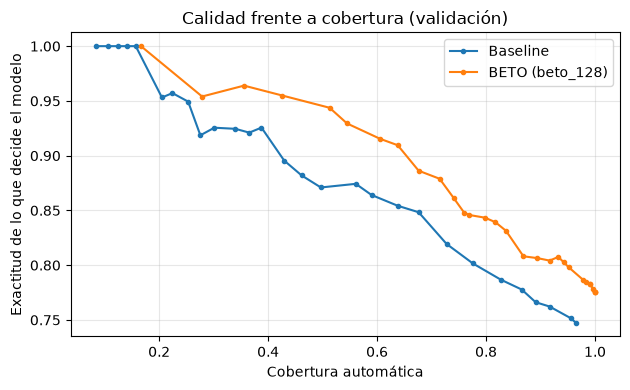

ECE (error de calibración) en validación: {'baseline': np.float64(0.121), 'beto': np.float64(0.058)}


In [13]:
def reglas(nombre, Pv, Pt):
    mejor, grilla = elegir_regla(yva, Pv, META['recall_critica'])
    rv = evaluar_regla(yva, Pv, mejor.tau, mejor.t_neg); rt = evaluar_regla(yte, Pt, mejor.tau, mejor.t_neg)
    return dict(modelo=nombre, tau=mejor.tau, t_neg=mejor.t_neg,
                cobertura_val=rv['cobertura'], recall_queja_con_revision_val=rv['recall_queja_con_revision'],
                cobertura_test=rt['cobertura'], revision_test=rt['revision'], exactitud_automatica_test=rt['exactitud_automatica'],
                recall_queja_directo_test=rt['recall_queja_directo'], recall_queja_con_revision_test=rt['recall_queja_con_revision']), grilla
fila_b, grilla_b = reglas('Baseline', Pva_base, Pte_base); filas_r = [fila_b]
if Pte_beto is not None:
    fila_r, grilla_r = reglas(f'BETO ({BETO_CFG})', Pva_beto, Pte_beto); filas_r.append(fila_r)
tabla_abst = pd.DataFrame(filas_r); display(tabla_abst.round(3)); tabla_abst.to_csv(ruta_res('abstencion.csv'), index=False)
# curva calidad-cobertura (solo variando la confianza, sin regla de queja)
fig, ax = plt.subplots(figsize=(6.4, 4))
for nombre, Pv in [('Baseline', Pva_base)] + ([(f'BETO ({BETO_CFG})', Pva_beto)] if Pva_beto is not None else []):
    xs, ys = [], []
    for tau in np.arange(0.35, 0.97, 0.02):
        a_ = Pv.max(1) >= tau
        if a_.sum() > 15: xs.append(a_.mean()); ys.append((Pv.argmax(1) == yva)[a_].mean())
    ax.plot(xs, ys, marker='o', ms=3, label=nombre)
ax.set_xlabel('Cobertura automática'); ax.set_ylabel('Exactitud de lo que decide el modelo'); ax.set_title('Calidad frente a cobertura (validación)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print('ECE (error de calibración) en validación:', {'baseline': round(ece(yva, Pva_base), 3), **({'beto': round(ece(yva, Pva_beto), 3)} if Pva_beto is not None else {})})

### 9.1 Comparación con la misma carga de revisión (validación)
**Por qué:** con el mismo umbral de confianza (0,50), el baseline manda a revisión muchos más casos que BETO, y eso hace que los recalls no sean comparables. Aquí se fija **el mismo porcentaje de casos a revisión** (los de menor confianza) y se compara cuántas quejas se encuentran y qué tan exacto es lo que el modelo decide solo. Se hace en **validación**, no en test.
**Cómo leerlo:** son pocas quejas (57 en validación) y una sola corrida de BETO (la de la semilla 42): es un indicio, no una prueba.

In [14]:
def carga_revision(P, frac):
    conf = P.max(1); k = int(round(frac * len(P))); rev = np.zeros(len(P), bool); rev[np.argsort(conf)[:k]] = True
    pred = P.argmax(1); q = (yva == IDX[CRITICA]); det = ((pred == IDX[CRITICA]) | rev) & q; auto = ~rev
    return dict(quejas_encontradas=int(det.sum()), quejas_totales=int(q.sum()), recall_queja_con_revision=float(det.sum() / q.sum()),
                exactitud_automatica=float((pred[auto] == yva[auto]).mean()))
if Pva_beto is not None:
    filas_c = []
    for nombre, Pv_ in [('Baseline', Pva_base), ('BETO', Pva_beto)]:
        for fr in (0.05, 0.10, 0.15, 0.20, 0.31, 0.40): filas_c.append(dict(revision_pct=int(round(fr * 100)), modelo=nombre, **carga_revision(Pv_, fr)))
    tabla_c = pd.DataFrame(filas_c); tabla_c.to_csv(ruta_res('carga_revision_validacion.csv'), index=False)
    display(tabla_c.pivot(index='revision_pct', columns='modelo', values=['recall_queja_con_revision', 'exactitud_automatica']).round(3))
else:
    print('Sin BETO no hay comparación.')

recall_queja_con_revision          exactitud_automatica         
modelo                            BETO Baseline                 BETO Baseline
revision_pct                                                                 
5                                0.912    0.825                0.801    0.753
10                               0.912    0.842                0.804    0.765
15                               0.930    0.877                0.826    0.785
20                               0.930    0.912                0.840    0.796
31                               0.947    0.982                0.888    0.837
40                               0.965    0.982                0.914    0.861

**Cómo leerlo.** `cobertura` es la fracción de comentarios que el sistema decide solo; `recall_queja_con_revision` cuenta como encontrada una queja que el modelo clasificó bien **o** que mandó a revisión. Una regla que cumple la meta en validación pero la incumple en test indica que el umbral no se generaliza: es la señal para ajustarlo en el piloto, no para modificarlo ahora.

### Guardia para textos fuera de dominio
La confianza no basta: un texto sin sentido como `asdkjh qwerty` puede recibir una confianza mayor que el umbral. Por eso se agrega una **segunda condición de revisión**: si menos del 60 % de las palabras del comentario aparece en el vocabulario de entrenamiento (palabras que se repiten en al menos 2 reseñas), o si se reconocen menos de 2 palabras, el caso pasa a una persona. La guardia se mide aquí con validación y test.

In [15]:
from collections import Counter
def toks(t): return re.findall(r'(?u)\b\w\w+\b', t.lower())
VOCAB_OOD = {w for w, c in Counter(w for t in tr.texto for w in set(toks(t))).items() if c >= 2}
COB_MIN, MIN_CONOCIDAS = 0.60, 2
def cobertura_vocab(t):
    k = toks(t); return (sum(w in VOCAB_OOD for w in k) / len(k)) if k else 0.0
def fuera_dominio(textos): return np.array([(cobertura_vocab(t) < COB_MIN) or (sum(w in VOCAB_OOD for w in toks(t)) < MIN_CONOCIDAS) for t in textos])
fv, ft = fuera_dominio(va.texto), fuera_dominio(te.texto)
tau_b = float(tabla_abst.iloc[0].tau); t_neg_b = float(tabla_abst.iloc[0].t_neg)
def con_guardia(y, P, fd):
    rev = regla_revision(P, tau_b, t_neg_b) | fd; pred = P.argmax(1); q = (y == IDX[CRITICA])
    return dict(revision=rev.mean(), cobertura=1 - rev.mean(), exactitud_automatica=(pred == y)[~rev].mean(), recall_queja_con_revision=(((pred == IDX[CRITICA]) | rev) & q).sum() / q.sum())
g_ = pd.DataFrame({'solo confianza (validación)': {k: v for k, v in evaluar_regla(yva, Pva_base, tau_b, t_neg_b).items() if k in ('revision', 'cobertura', 'exactitud_automatica', 'recall_queja_con_revision')},
                   'confianza + guardia (validación)': con_guardia(yva, Pva_base, fv),
                   'solo confianza (test)': {k: v for k, v in evaluar_regla(yte, Pte_base, tau_b, t_neg_b).items() if k in ('revision', 'cobertura', 'exactitud_automatica', 'recall_queja_con_revision')},
                   'confianza + guardia (test)': con_guardia(yte, Pte_base, ft)}).T
display(g_.round(3))
print(f'La guardia marca {fv.mean():.1%} de las reseñas de validación y {ft.mean():.1%} de las de test.')
casos_fd = pd.DataFrame({'texto': FUERA.texto if 'FUERA' in globals() else ['La fotosíntesis depende de la luz solar', 'asdkjh qwerty', '😀😀😀', 'The service was great and the food too', '12345 67890', 'Compro y vendo autos usados']})
casos_fd['confianza'] = base.predict_proba(casos_fd.texto).max(1).round(2); casos_fd['revisión por confianza'] = casos_fd.confianza < tau_b
casos_fd['revisión por guardia'] = fuera_dominio(casos_fd.texto); casos_fd['revisión final'] = casos_fd['revisión por confianza'] | casos_fd['revisión por guardia']
display(casos_fd)
json.dump(dict(tau=tau_b, t_neg=t_neg_b, cobertura_min=COB_MIN, min_conocidas=MIN_CONOCIDAS, vocabulario=sorted(VOCAB_OOD)), open(ruta_res('regla_abstencion.json'), 'w', encoding='utf-8'), ensure_ascii=False)

,cobertura,revision,exactitud_automatica,recall_queja_con_revision
solo confianza (validación),0.699,0.301,0.830,0.965
confianza + guardia (validación),0.683,0.317,0.831,0.965
solo confianza (test),0.686,0.314,0.813,0.932
confianza + guardia (test),0.679,0.321,0.811,0.932


La guardia marca 3.5% de las reseñas de validación y 1.3% de las de test.


,texto,confianza,revisión por confianza,revisión por guardia,revisión final
0,La fotosíntesis depende de la luz solar,0.56,False,True,True
1,asdkjh qwerty,0.60,False,True,True
2,😀😀😀,0.66,False,True,True
3,The service was great and the food too,0.51,False,True,True
4,12345 67890,0.65,False,True,True
5,Compro y vendo autos usados,0.38,True,True,True


**Cómo leerlo.** La guardia agrega pocas revisiones sobre las reseñas reales y atrapa los textos sin relación con el casino. No detecta todo: una frase en español común (como la de la fotosíntesis) puede pasar si usa palabras frecuentes; por eso el monitoreo debe vigilar también la distribución de confianza y de longitud.

## 10. Análisis de errores
**Qué hacemos:** revisamos al menos 10 errores del **modelo recomendado** en **validación** (no en test), ordenados por la confianza con que se equivocó, y los clasificamos por causa probable.
**Por qué:** la causa dicta la solución: más datos, corregir etiquetas, cambiar la longitud o cambiar la arquitectura. La columna `causa_revisada` la completa el equipo a mano.

In [16]:
MODELO_FINAL = 'beto' if Pva_beto is not None else 'baseline'
Pv = Pva_beto if MODELO_FINAL == 'beto' else Pva_base
pred = Pv.argmax(1); mal = pred != yva
err = va[mal].assign(pred=[CLASES[i] for i in pred[mal]], confianza=Pv.max(1)[mal].round(3))
def causa(r):
    t = r.texto.lower(); c = []
    if r.n_palabras > 64: c.append('largo')
    if {r.sentimiento, r.pred} <= {'positiva', 'no_mencionado'}: c.append('etiqueta ambigua (positiva / no_mencionado)')
    if re.search(r'\b(pero|aunque|sin embargo|eso sí)\b', t): c.append('contraste')
    if re.search(r'\b(no|nunca|ni|tampoco|sin)\b', t): c.append('negación')
    if sum(ch.isupper() for ch in r.texto) > 0.6 * max(1, sum(ch.isalpha() for ch in r.texto)): c.append('MAYÚSCULAS')
    return ' + '.join(c) if c else 'otra (revisar)'
err['causa_probable'] = [causa(r) for r in err.itertuples()]; err['causa_revisada'] = ''
print(f'Modelo analizado: {MODELO_FINAL} | errores en validación: {mal.sum()} de {len(va)} ({mal.mean():.1%})')
display(err.sort_values('confianza', ascending=False)[['id', 'sentimiento', 'pred', 'confianza', 'causa_probable', 'texto']].head(15).assign(texto=lambda d: d.texto.str[:110]))
print('\nCausas probables (puede haber más de una por error):')
display(err.causa_probable.str.split(' \+ ').explode().value_counts().to_frame('errores'))
print('Confusiones más frecuentes (real → predicho):'); display(err.groupby(['sentimiento', 'pred']).size().sort_values(ascending=False).head(6).to_frame('errores'))
err.sort_values('confianza', ascending=False).to_csv(ruta_res(f'errores_validacion_{MODELO_FINAL}.csv'), index=False, encoding='utf-8-sig')

Modelo analizado: beto | errores en validación: 70 de 312 (22.4%)


,id,sentimiento,pred,confianza,causa_probable,texto
152,6902,no_mencionado,negativa,0.927,negación,Buen lugar para dejar nuestro dinero. Faltan ruletas en sector no fumadores
270,12751,no_mencionado,positiva,0.926,etiqueta ambigua (positiva / no_mencionado),Histórico edificio lleno de valores artísticos; excelente para recorrer y disfrutar!
157,7171,negativa,mixta,0.918,otra (revisar),Excelente lugar.. los costos de comida son pasable.... muchas veces tenes que esperar a que te l...
100,4437,mixta,negativa,0.914,contraste + negación,Mucha variedad de máquinas; pero el lugar es muy sucio. Papeles; vasos descartables; etc por los...
264,12445,positiva,no_mencionado,0.876,etiqueta ambigua (positiva / no_mencionado),Excelente lugar para apostar
209,9481,positiva,no_mencionado,0.876,etiqueta ambigua (positiva / no_mencionado),Recital de Pablo Alboran 💙💙💙💙💙
216,9859,positiva,no_mencionado,0.856,etiqueta ambigua (positiva / no_mencionado),Hippodromo de Palermo perfecto!
39,1438,positiva,no_mencionado,0.856,etiqueta ambigua (positiva / no_mencionado),Un espectáculo de lugar
36,1359,positiva,no_mencionado,0.853,etiqueta ambigua (positiva / no_mencionado),Se la pasa re bien!!!
35,1348,no_mencionado,positiva,0.846,etiqueta ambigua (positiva / no_mencionado),Excelente lugar muy bueno para hacer una salida fotos juegos



Causas probables (puede haber más de una por error):


,errores
causa_probable,
etiqueta ambigua (positiva / no_mencionado),44
negación,15
contraste,13
otra (revisar),8
MAYÚSCULAS,2


Confusiones más frecuentes (real → predicho):


errores
sentimiento   pred                  
positiva      no_mencionado       28
no_mencionado positiva            16
negativa      mixta                7
positiva      mixta                6
mixta         positiva             4
              negativa             3

## 11. Pruebas de robustez
**Qué hacemos:** probamos el modelo con (a) **pares de frases** que cambian una sola cosa (negación, contraste, orden, ortografía, mayúsculas), (b) **perturbaciones plausibles** sobre las reseñas reales de validación (sin tildes, MAYÚSCULAS, errores de tipeo, abreviaturas) y (c) **entradas fuera de dominio**.
**Por qué:** las métricas generales no muestran si el modelo entiende una negación o ignora una falta de ortografía, ni qué hace con un texto que no es una reseña. Estas pruebas deben repetirse como regresiones cada vez que cambie el modelo.

In [17]:
def sin_tildes(t):
    t = t.replace('ñ', '\u0001').replace('Ñ', '\u0002')
    t = ''.join(c for c in unicodedata.normalize('NFD', t) if unicodedata.category(c) != 'Mn'); return t.replace('\u0001', 'ñ').replace('\u0002', 'Ñ')
def tipeo(t, rng, prob=0.15):
    pal = t.split(' ')
    for i, w in enumerate(pal):
        if len(w) >= 5 and w.isalpha() and rng.random() < prob:
            j = rng.integers(1, len(w) - 2); pal[i] = w[:j] + w[j + 1] + w[j] + w[j + 2:]
    return ' '.join(pal)
ABREV = [(r'\bporque\b', 'xq'), (r'\bpor\b', 'x'), (r'\bque\b', 'q'), (r'\btambién\b', 'tb'), (r'\bbien\b', 'bn')]
def abrevia(t):
    for p_, r_ in ABREV: t = re.sub(p_, r_, t, flags=re.IGNORECASE)
    return t
def variantes(textos, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    return {'original': list(textos), 'sin tildes': [sin_tildes(t) for t in textos], 'MAYÚSCULAS': [t.upper() for t in textos],
            'errores de tipeo': [tipeo(t, rng) for t in textos], 'abreviaturas': [abrevia(t) for t in textos]}
VAR = variantes(va.texto)
display(pd.DataFrame({k: v[:3] for k, v in VAR.items()}).T)   # ejemplos de las perturbaciones
# Casos de pares (archivo del equipo) y fuera de dominio
ruta_c = buscar('casos_robustez.csv'); casos = pd.read_csv(ruta_c)
FUERA = pd.DataFrame({'par': 100 + np.arange(6), 'tipo': 'fuera de dominio', 'esperado': 'no_mencionado',
                      'texto': ['La fotosíntesis depende de la luz solar', 'asdkjh qwerty', '😀😀😀', 'The service was great and the food too', '12345 67890', 'Compro y vendo autos usados']})
casos = pd.concat([casos[['par', 'tipo', 'texto', 'esperado']], FUERA], ignore_index=True)
Pc_base = base.predict_proba(casos.texto)
def tabla_casos(P, nombre):
    d = casos.copy(); d['prediccion'] = [CLASES[i] for i in P.argmax(1)]; d['confianza'] = P.max(1).round(3); d['acierta'] = d.prediccion == d.esperado; d['modelo'] = nombre; return d
rob = {'Baseline': tabla_casos(Pc_base, 'Baseline')}
if BETO_LISTO and os.path.exists(ruta_res('beto_robustez.csv')) and not ENTRENAR_BETO:
    rb = pd.read_csv(ruta_res('beto_robustez.csv')); rob['BETO'] = tabla_casos(rb[CLASES].values, 'BETO')
elif BETO_LISTO and ENTRENAR_BETO:
    par = CONFIGS_BETO[BETO_CFG]; pr = Predictor(carpeta_modelo(BETO_CFG, SEMILLAS[0]), par['max_len'], par['minusculas'])
    Pc_b = pr(casos.texto); pd.DataFrame(Pc_b, columns=CLASES).to_csv(ruta_res('beto_robustez.csv'), index=False); rob['BETO'] = tabla_casos(Pc_b, 'BETO')
    pert = []
    for nombre_v, tx in VAR.items(): pert.append(pd.DataFrame(pr(tx), columns=CLASES).assign(variante=nombre_v, id=va.id.values))
    pd.concat(pert).to_csv(ruta_res('beto_perturbaciones.csv'), index=False); del pr; gc.collect(); torch.cuda.empty_cache()
tabla_r = pd.concat(rob.values())
display(tabla_r.pivot_table(index='tipo', columns='modelo', values='acierta', aggfunc='sum').join(casos.groupby('tipo').size().rename('frases')))
display(tabla_r[tabla_r.modelo == list(rob)[-1]][['par', 'tipo', 'texto', 'esperado', 'prediccion', 'confianza', 'acierta']].assign(texto=lambda d: d.texto.str[:70]))
tabla_r.to_csv(ruta_res('robustez_pares.csv'), index=False, encoding='utf-8-sig')

,0,1,2
original,Todo excelente ; lo mejor es la atención; sobre todo la gente de la barra; están atentos a tus n...,Siguen robándole a la gente. Ojo; ellos son las víctimas y jamás te obligan. pero; hacen 2.000.0...,Muy buen. Restaurante
sin tildes,Todo excelente ; lo mejor es la atencion; sobre todo la gente de la barra; estan atentos a tus n...,Siguen robandole a la gente. Ojo; ellos son las victimas y jamas te obligan. pero; hacen 2.000.0...,Muy buen. Restaurante
MAYÚSCULAS,TODO EXCELENTE ; LO MEJOR ES LA ATENCIÓN; SOBRE TODO LA GENTE DE LA BARRA; ESTÁN ATENTOS A TUS N...,SIGUEN ROBÁNDOLE A LA GENTE. OJO; ELLOS SON LAS VÍCTIMAS Y JAMÁS TE OBLIGAN. PERO; HACEN 2.000.0...,MUY BUEN. RESTAURANTE
errores de tipeo,Todo excelente ; lo mejor es la atención; sobre todo la gente de la barra; esátn atentos a tus n...,Siguen robándole a la gente. Ojo; ellos son las víctimas y jamás te obligan. pero; hacen 2.000.0...,Muy buen. Restaurante
abreviaturas,Todo excelente ; lo mejor es la atención; sobre todo la gente de la barra; están atentos a tus n...,Siguen robándole a la gente. Ojo; ellos son las víctimas y jamás te obligan. pero; hacen 2.000.0...,Muy buen. Restaurante


,BETO,Baseline,frases
tipo,,,
contraste,5,5,5
doble negación,0,0,1
fuera de dominio,5,6,6
fuera del tema,1,1,1
ironía,1,1,2
mayúsculas y emojis,1,2,2
negación,8,8,10
orden,2,0,2
ortografía,3,3,3


,par,tipo,texto,esperado,prediccion,confianza,acierta
0,1,negación,La comida es muy rica,positiva,positiva,0.825,True
1,1,negación,La comida no es para nada rica,negativa,negativa,0.933,True
2,2,negación,Las máquinas pagan bien,positiva,negativa,0.548,False
3,2,negación,Las máquinas no pagan nunca,negativa,negativa,0.962,True
4,3,negación,La atención fue excelente,positiva,positiva,0.636,True
5,3,negación,La atención no fue nada buena,negativa,negativa,0.876,True
6,4,negación,El lugar está muy limpio,positiva,positiva,0.850,True
7,4,negación,"El lugar no está limpio, los baños un asco",negativa,negativa,0.919,True
8,5,negación,Me sentí seguro todo el tiempo,positiva,no_mencionado,0.813,False
9,5,negación,"No me sentí seguro, había gente rara en la entrada",negativa,negativa,0.811,True


In [18]:
# Perturbaciones sobre validación: cuánto cae el F1 macro y cuántas predicciones cambian
def tabla_pert(nombre, fn_probs):
    P0 = fn_probs('original'); filas = []
    for v in VAR:
        P = fn_probs(v); m = metricas(yva, P)
        filas.append(dict(modelo=nombre, variante=v, f1_macro=round(m['f1_macro'], 3), recall_negativa=round(m['recall_negativa'], 3),
                          cambian_pct=0.0 if v == 'original' else round((P.argmax(1) != P0.argmax(1)).mean() * 100, 1)))
    return pd.DataFrame(filas)
tp_base = tabla_pert('Baseline', lambda v: base.predict_proba(VAR[v]))
partes = [tp_base]
if BETO_LISTO and os.path.exists(ruta_res('beto_perturbaciones.csv')):
    pp = pd.read_csv(ruta_res('beto_perturbaciones.csv'))
    partes.append(tabla_pert('BETO', lambda v: pp[pp.variante == v].set_index('id').loc[va.id.values][CLASES].values))
tp_all = pd.concat(partes)
display(tp_all.pivot(index='modelo', columns='variante', values='f1_macro')[list(VAR)])
display(tp_all[tp_all.variante != 'original'].pivot(index='modelo', columns='variante', values='cambian_pct'))
tp_all.to_csv(ruta_res('robustez_perturbaciones.csv'), index=False)

variante,original,sin tildes,MAYÚSCULAS,errores de tipeo,abreviaturas
modelo,,,,,
BETO,0.706,0.701,0.478,0.701,0.708
Baseline,0.646,0.647,0.646,0.616,0.640


variante,MAYÚSCULAS,abreviaturas,errores de tipeo,sin tildes
modelo,,,,
BETO,42.9,1.3,5.1,2.6
Baseline,0.0,1.3,4.2,3.8


## 12. Desempeño por segmentos
**Qué hacemos:** medimos el modelo recomendado en **validación** por longitud de la reseña y por periodo.
**Por qué:** un buen promedio puede esconder que el modelo falla con los textos largos o con un periodo concreto. Con un solo lugar y un solo canal, estos son los segmentos pertinentes; no hay segmentos de sede o canal.

In [19]:
seg = va.assign(pred=Pv.argmax(1), ok=(Pv.argmax(1) == yva))
seg['longitud'] = pd.cut(seg.n_palabras, [0, 5, 12, 30, 1000], labels=['1-5 palabras', '6-12', '13-30', 'más de 30'])
seg['periodo_grupo'] = pd.cut(seg.periodo.str[:4].astype(int), [2015, 2019, 2021, 2030], labels=['2016-2019', '2020-2021', '2022-2024'])
def resumen_seg(col):
    g = seg.groupby(col, observed=True)
    return pd.DataFrame({'reseñas': g.size(), 'exactitud': g.ok.mean().round(3),
                         'F1 macro': g.apply(lambda x: round(f1_score(x.y, x.pred, average='macro', labels=list(range(4)), zero_division=0), 3)),
                         'quejas': g.apply(lambda x: int((x.y == IDX[CRITICA]).sum())),
                         'recall de quejas': g.apply(lambda x: round(((x.pred == IDX[CRITICA]) & (x.y == IDX[CRITICA])).sum() / max(1, (x.y == IDX[CRITICA]).sum()), 3))})
print('Modelo analizado:', MODELO_FINAL); display(resumen_seg('longitud')); display(resumen_seg('periodo_grupo'))
pd.concat([resumen_seg('longitud').reset_index().rename(columns={'longitud': 'segmento'}).assign(tipo='longitud'),
           resumen_seg('periodo_grupo').reset_index().rename(columns={'periodo_grupo': 'segmento'}).assign(tipo='periodo')]).to_csv(ruta_res('segmentos_validacion.csv'), index=False)

Modelo analizado: beto


,reseñas,exactitud,F1 macro,quejas,recall de quejas
longitud,,,,,
1-5 palabras,84,0.714,0.686,6,0.833
6-12,125,0.816,0.743,20,0.950
13-30,67,0.791,0.641,17,0.824
más de 30,36,0.750,0.562,14,0.786


,reseñas,exactitud,F1 macro,quejas,recall de quejas
periodo_grupo,,,,,
2016-2019,144,0.799,0.766,23,0.913
2020-2021,58,0.724,0.601,16,0.812
2022-2024,110,0.773,0.693,18,0.833


## 13. Costo, latencia y operación
**Qué hacemos:** medimos tamaño, tiempo de entrenamiento y latencia por comentario (uno a la vez), y el volumen que atiende cada modelo.
**Por qué:** la decisión de adoptar BETO no depende solo de la calidad: depende de cuánto cuesta servirlo y de si responde a tiempo.

In [20]:
def latencia(fn, textos, n=60):
    m = list(textos)[:n]
    for t in m[:5]: fn([t])
    ms = []
    for t in m:
        t0 = time.perf_counter(); fn([t]); ms.append((time.perf_counter() - t0) * 1000)
    return float(np.percentile(ms, 50)), float(np.percentile(ms, 95))
p50, p95 = latencia(base.predict_proba, va.texto)
joblib.dump(base, ruta_res('baseline_modelo.joblib')); tam = os.path.getsize(ruta_res('baseline_modelo.joblib')) / 1e6
def n_coef(pipe):
    v = pipe.named_steps['v']
    n = sum(len(x.vocabulary_) for _, x in v.transformer_list) if hasattr(v, 'transformer_list') else len(v.vocabulary_)
    return n * 4
costo = [dict(modelo='Baseline', parametros=f"{n_coef(base) / 1e6:.2f} M coeficientes", tamano_MB=round(tam, 1), entrenamiento_s=round(tiempos[BASE_NOMBRE], 1),
              latencia_p50_ms=round(p50, 1), latencia_p95_ms=round(p95, 1), hardware='CPU de este equipo')]
if BETO_LISTO:
    lat_b = ruta_res('beto_latencia.json')
    if ENTRENAR_BETO:
        par = CONFIGS_BETO[BETO_CFG]; pr = Predictor(carpeta_modelo(BETO_CFG, SEMILLAS[0]), par['max_len'], par['minusculas']); g50, g95 = latencia(pr, va.texto)
        pc = Predictor(carpeta_modelo(BETO_CFG, SEMILLAS[0]), par['max_len'], par['minusculas'], 'cpu'); c50, c95 = latencia(pc, va.texto, n=30)
        json.dump(dict(gpu_p50=g50, gpu_p95=g95, cpu_p50=c50, cpu_p95=c95, gpu=torch.cuda.get_device_name(0)), open(lat_b, 'w'))
    if os.path.exists(lat_b):
        L = json.load(open(lat_b)); cb = pd.read_csv(ruta_res('beto_corridas.csv')); cb = cb[cb.config == BETO_CFG]
        costo.append(dict(modelo='BETO', parametros=f"{cb.parametros_M.iloc[0]} M", tamano_MB='≈ 440', entrenamiento_s=round(cb.segundos_entrenamiento.mean(), 1),
                          latencia_p50_ms=f"GPU {L['gpu_p50']:.1f} · CPU {L['cpu_p50']:.1f}", latencia_p95_ms=f"GPU {L['gpu_p95']:.1f} · CPU {L['cpu_p95']:.1f}", hardware=L.get('gpu', 'GPU')))
tabla_costo = pd.DataFrame(costo); display(tabla_costo)
tabla_costo.to_csv(ruta_res('costo_latencia.csv'), index=False)

,modelo,parametros,tamano_MB,entrenamiento_s,latencia_p50_ms,latencia_p95_ms,hardware
0,Baseline,0.07 M coeficientes,0.9,2.1,6.3,8.2,CPU de este equipo
1,BETO,109.9 M,≈ 440,65.1,GPU 7.5 · CPU 110.0,GPU 8.9 · CPU 143.0,Tesla T4


## 14. Criterios de adopción, conclusiones y recomendación
**Qué hacemos:** comparamos los resultados con las metas **provisionales** y escribimos la recomendación: mantener el baseline, hacer un piloto o adoptar BETO.
**Por qué:** el lineamiento pide una recomendación condicionada, con evidencia y con el criterio que obligaría a suspenderla.

In [21]:
def cumple(x, ok): return '✓' if ok else '✗'
b_f1 = res_test.f1_macro.iloc[0]
filas = []
if Pte_beto is not None:
    mb = res_test[res_test.modelo.str.startswith('BETO')]; dF = mb.f1_macro.mean() - b_f1
    rec_b = tabla_abst.iloc[1]['recall_queja_con_revision_test']; cob_b = tabla_abst.iloc[1]['cobertura_test']
    filas += [['Mejora de F1 macro de BETO sobre el baseline (test)', f"≥ +{META['mejora_f1']:.2f}", f"{dF:+.3f}", cumple(0, dF >= META['mejora_f1'])],
              ['Recall de quejas con revisión humana (BETO, test)', f"≥ {META['recall_critica']:.2f}", f"{rec_b:.3f}", cumple(0, rec_b >= META['recall_critica'])],
              ['Cobertura automática (BETO, test)', f"≥ {META['cobertura']:.0%}", f"{cob_b:.1%}", cumple(0, cob_b >= META['cobertura'])]]
rec_0 = tabla_abst.iloc[0]['recall_queja_con_revision_test']; cob_0 = tabla_abst.iloc[0]['cobertura_test']
filas += [['Recall de quejas con revisión humana (baseline, test)', f"≥ {META['recall_critica']:.2f}", f"{rec_0:.3f}", cumple(0, rec_0 >= META['recall_critica'])],
          ['Cobertura automática (baseline, test)', f"≥ {META['cobertura']:.0%}", f"{cob_0:.1%}", cumple(0, cob_0 >= META['cobertura'])]]
crit = pd.DataFrame(filas, columns=['criterio (provisional)', 'meta', 'resultado', 'cumple']); display(crit)
crit.to_csv(ruta_res('criterios_adopcion.csv'), index=False, encoding='utf-8-sig')

,criterio (provisional),meta,resultado,cumple
0,Mejora de F1 macro de BETO sobre el baseline (test),≥ +0.02,+0.081,✓
1,"Recall de quejas con revisión humana (BETO, test)",≥ 0.90,0.881,✗
2,"Cobertura automática (BETO, test)",≥ 75%,94.9%,✓
3,"Recall de quejas con revisión humana (baseline, test)",≥ 0.90,0.932,✓
4,"Cobertura automática (baseline, test)",≥ 75%,68.6%,✗


### Conclusiones (se actualizan con los resultados)
Las conclusiones que siguen se generan a partir de las tablas anteriores. Si BETO aún no se ha ejecutado, solo se describe el baseline y se indica qué falta.

In [22]:
L = []
L.append(f"Baseline ({BASE_NOMBRE}): F1 macro {res_test.f1_macro.iloc[0]:.3f} en test; recall de quejas {res_test.recall_negativa.iloc[0]:.3f} sin revisión y {tabla_abst.iloc[0]['recall_queja_con_revision_test']:.3f} con revisión humana, con cobertura automática de {tabla_abst.iloc[0]['cobertura_test']:.1%}.")
if Pte_beto is not None:
    mb = res_test[res_test.modelo.str.startswith('BETO')]
    L.append(f"BETO ({BETO_CFG}): F1 macro {mb.f1_macro.mean():.3f} ± {mb.f1_macro.std():.3f} en test (3 semillas); recall de quejas {mb.recall_negativa.mean():.3f} sin revisión y {tabla_abst.iloc[1]['recall_queja_con_revision_test']:.3f} con revisión, con cobertura de {tabla_abst.iloc[1]['cobertura_test']:.1%}.")
    L.append(f"Diferencia BETO − baseline en F1 macro: {r['diff']:+.3f} (IC95 % {r['diff_ic'][0]:+.3f} a {r['diff_ic'][1]:+.3f}). " + ("El intervalo no incluye el 0: la mejora no es ruido." if r['diff_ic'][0] > 0 else "El intervalo incluye el 0: no hay evidencia suficiente de que BETO sea mejor."))
else:
    L.append('BETO todavía no se ha ejecutado: la comparación con el modelo avanzado queda pendiente hasta tener los resultados de Colab.')
L.append(f"El test tiene {int((yte == IDX['negativa']).sum())} quejas y {int((yte == IDX['mixta']).sum())} reseñas mixtas: las diferencias pequeñas no son concluyentes.")
for x in L: print('•', x)

# ---- Resumen consolidado (fuente única para el informe y la presentación)
resumen = dict(semilla=SEMILLA, n=dict(train=len(tr), validation=len(va), test=len(te), quejas_test=int((yte == IDX['negativa']).sum()), mixtas_test=int((yte == IDX['mixta']).sum())),
               baseline=dict(nombre=BASE_NOMBRE, f1_val=float(comp_val.f1_macro.iloc[0]), f1_test=float(res_test.f1_macro.iloc[0]), recall_test=float(res_test.recall_negativa.iloc[0]),
                             f1_mixta_test=float(res_test.f1_mixta.iloc[0]), log_loss_test=float(res_test.log_loss.iloc[0]), ic_f1=ic_base['f1_macro'], ic_recall=ic_base['recall_negativa']),
               beto=None, abstencion=[{k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in fila.items()} for fila in tabla_abst.to_dict('records')], meta=META)
if Pte_beto is not None:
    mb = res_test[res_test.modelo.str.startswith('BETO')]; fv = comp_val[comp_val.modelo.str.contains(BETO_CFG)].iloc[0]
    resumen['beto'] = dict(config=BETO_CFG, f1_val=float(fv.f1_macro), f1_test_media=float(mb.f1_macro.mean()), f1_test_std=float(mb.f1_macro.std()), recall_test_media=float(mb.recall_negativa.mean()),
                           f1_mixta_media=float(mb.f1_mixta.mean()), log_loss_media=float(mb.log_loss.mean()), diff=float(r['diff']), diff_ic=[float(x) for x in r['diff_ic']],
                           ic_f1=[float(x) for x in r['b']], p_mejor=float(r['p_b_mejor']))
def decidir():
    if resumen['beto'] is None: return 'pendiente_beto'
    ab = tabla_abst.iloc[1]; mejora = resumen['beto']['diff_ic'][0] > 0
    ok = mejora and ab.recall_queja_con_revision_test >= META['recall_critica'] and ab.cobertura_test >= META['cobertura']
    return 'piloto_sombra_beto' if ok else ('piloto_ambos_modelos' if mejora else 'mantener_baseline')
resumen['decision'] = decidir(); print('Decisión sugerida por las reglas provisionales:', resumen['decision'])
json.dump(resumen, open(ruta_res('resumen_final.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
json.dump(dict(semilla=SEMILLA, baseline=BASE_NOMBRE, beto_config=BETO_CFG, beto_listo=bool(Pte_beto is not None), meta=META,
               versiones=dict(python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__), conclusiones=L),
          open(ruta_res('configuracion_y_conclusiones.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)

• Baseline (TF-IDF caracteres y palabras + regresión logística): F1 macro 0.626 en test; recall de quejas 0.797 sin revisión y 0.932 con revisión humana, con cobertura automática de 68.6%.
• BETO (beto_128): F1 macro 0.707 ± 0.011 en test (3 semillas); recall de quejas 0.876 sin revisión y 0.881 con revisión, con cobertura de 94.9%.
• Diferencia BETO − baseline en F1 macro: +0.072 (IC95 % +0.003 a +0.145). El intervalo no incluye el 0: la mejora no es ruido.
• El test tiene 59 quejas y 19 reseñas mixtas: las diferencias pequeñas no son concluyentes.
Decisión sugerida por las reglas provisionales: piloto_ambos_modelos


### Recomendación (según las reglas provisionales; la decisión final es del equipo y de Gerencia IA)

| Opción | Cuándo se elige |
| --- | --- |
| **Mantener el baseline** | BETO no supera al baseline con claridad (intervalo de la diferencia que incluye 0) o no cumple el recall de quejas con una cobertura razonable. |
| **Piloto en modo sombra** | BETO mejora el F1 y, con abstención, alcanza el recall de quejas con cobertura suficiente; el modelo corre en paralelo sin decidir y se compara con las decisiones humanas. |
| **Piloto con ambos modelos** | BETO mejora el F1 y necesita menos revisión para un recall parecido, pero no cumple solo las metas en test: ambos corren en paralelo sin decidir y se comparan con una muestra auditada. |
| **Adoptar** | Solo tras un piloto que confirme las metas con datos reales de producción. |

**Condiciones de suspensión:** el recall de quejas baja del umbral acordado en el monitoreo; la carga de revisión supera la capacidad del equipo; o cambia el tipo de comentarios (otro canal, otro lugar).
**Siguiente experimento:** más reseñas anotadas (la mejora más segura), guía de etiquetado para `positiva` frente a `no_mencionado` y repetir la comparación.

## 15. Reproducibilidad y declaración de uso de IA generativa
- **Semilla:** 42 (y 43, 44). Versiones, parámetros y conclusiones se guardan en `results/configuracion_y_conclusiones.json`.
- **Datos anonimizados:** se enmascararon un teléfono y una firma con nombre propio.
- **Ejecución:** `requirements.txt` fija las versiones; la sección 6 entrena en GPU (Colab) o lee `results/beto_*`.
- **Uso de IA generativa:** el equipo usó un asistente de IA para generar el borrador del código y de la documentación. El equipo debe verificar el código, las cifras y las afirmaciones, y **solo las cifras que salen de ejecuciones guardadas en `results/` se presentan como evidencia experimental**.

In [23]:
# En Colab: empaqueta los resultados para llevarlos al repositorio (carpeta results/)
if EN_COLAB:
    import shutil
    zip_ = shutil.make_archive('results_colab', 'zip', CARPETA_RESULTADOS)
    from google.colab import files; files.download(zip_)
    print('Descomprime results_colab.zip dentro de results/ del repositorio y vuelve a ejecutar el notebook en tu computador.')
else:
    print('Resultados guardados en', os.path.abspath(CARPETA_RESULTADOS))

Resultados guardados en R:\EAN\Procesamiento de Lenguaje Natural\Proyecto Final\proyecto_final_casinos_nlp\results
